In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import scanpy.external as sce
import sys

sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
#sc.logging.print_versions()

#sc.settings.set_figure_params(dpi=80)
%matplotlib inline 
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower
sc.set_figure_params(scanpy=True, fontsize=14 )
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = ['sans-serif']
plt.rcParams['font.sans-serif'] = ['Arial']

In [2]:
import loompy as lp
import pandas as pd

In [3]:
lf = lp.connect("All_pyscenic_output.loom",  validate=False , mode='r+')

In [4]:
lf

In [5]:
lf.ca.CellID

array(['AAACCCACACCCTAGG-1-adata1', 'AAACCCAGTAAGGCTG-1-adata1',
       'AAACGAACAGTCGAGA-1-adata1', ..., 'AGTAGCTGTGCAATGG-1-adata8',
       'CAACCTCAGATGGGCT-1-adata8', 'CTGGTCTCACCGTACG-1-adata8'],
      dtype=object)

In [6]:
lf.ca.RegulonsAUC

array([(0.02735356, 0.0763852 , 0.        , 0.04621328, 0.04089219, 0.05414766, 0.08115692, 0., 0.        , 0.11296293, 0.00857576, 0.04072596, 0.01155393, 0.1055349 , 0.        , 0.07246934, 0.12762221, 0.1009532 , 0.        , 0.        , 0.10474214, 0.        , 0.        , 0.04048172, 0.10265534, 0.07184379, 0.        , 0.03820145, 0.        , 0.01289702, 0.        , 0.03061354, 0.20895291, 0.09561417, 0.02798947, 0.        , 0.11206044, 0.        , 0.00204461, 0.01656558, 0.11526549, 0.02071163, 0.00362896, 0.        , 0.        , 0.04608611, 0.04887787, 0.00925926, 0.10961444, 0.09908034, 0.06738742, 0.05956013, 0.07749818, 0.04483048, 0.03597937, 0.03568215, 0.02269502, 0.05452292, 0.0723002 , 0.07731729, 0.01089663, 0.00806927, 0.01635362, 0.        , 0.02742272, 0.05825156, 0.        , 0.12453532, 0.06671477, 0.01868314, 0.02447336, 0.03049042, 0.04379739, 0.05151839, 0.        , 0.0480255 , 0.01305705, 0.04290582, 0.03458958, 0.01496772, 0.03948585, 0.        , 0.03179289, 0.02

In [7]:
auc_mtx = pd.DataFrame( lf.ca.RegulonsAUC, index=lf.ca.CellID)

In [8]:
auc_mtx

,Ahdc1(+),Alx4(+),Ar(+),Arid3a(+),Arid5a(+),Arid5b(+),Arnt2(+),Ascl2(+),Atf1(+),Atf2(+),...,Zfp932(+),Zfp94(+),Zfp955a(+),Zfp961(+),Zfp990(+),Zfp992(+),Zfx(+),Zgpat(+),Zkscan2(+),Zkscan7(+)
AAACCCACACCCTAGG-1-adata1,0.027354,0.076385,0.000000,0.046213,0.040892,0.054148,0.081157,0.0,0.000000,0.112963,...,0.000000,0.000000,0.008877,0.0,0.0000,0.0,0.054211,0.0,0.000000,0.003548
AAACCCAGTAAGGCTG-1-adata1,0.024465,0.070720,0.000000,0.001604,0.004750,0.059439,0.070739,0.0,0.008536,0.080574,...,0.002097,0.000000,0.000000,0.0,0.0000,0.0,0.070886,0.0,0.000000,0.014053
AAACGAACAGTCGAGA-1-adata1,0.038205,0.274119,0.026771,0.015854,0.029189,0.054664,0.099882,0.0,0.000000,0.088115,...,0.000000,0.089736,0.000000,0.0,0.0000,0.0,0.051931,0.0,0.000000,0.054157
AAACGCTAGCAGCAGT-1-adata1,0.029396,0.026907,0.000671,0.022268,0.052664,0.065337,0.077972,0.0,0.000000,0.103687,...,0.000000,0.000000,0.000000,0.0,0.0000,0.0,0.063456,0.0,0.000000,0.000000
AAAGGATTCTGAATCG-1-adata1,0.023452,0.133386,0.001136,0.032619,0.000000,0.044829,0.073702,0.0,0.000000,0.060151,...,0.000000,0.000000,0.000113,0.0,0.0000,0.0,0.051569,0.0,0.000000,0.005238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CTGGTCTCACCGTACG-1-adata7,0.082178,0.049035,0.000000,0.077374,0.046400,0.080897,0.103304,0.0,0.000000,0.100841,...,0.029835,0.000000,0.019612,0.0,0.0000,0.0,0.065738,0.0,0.000000,0.023938
AATAGAGCACAGTGTT-1-adata8,0.032645,0.080811,0.008829,0.029193,0.034559,0.053767,0.082862,0.0,0.000000,0.075218,...,0.048851,0.000000,0.019308,0.0,0.0000,0.0,0.065517,0.0,0.000000,0.001155
AGTAGCTGTGCAATGG-1-adata8,0.069351,0.197823,0.000000,0.030979,0.000000,0.060793,0.079547,0.0,0.068016,0.081885,...,0.085407,0.072594,0.028546,0.0,0.0000,0.0,0.056132,0.0,0.000000,0.039033
CAACCTCAGATGGGCT-1-adata8,0.039837,0.175872,0.000000,0.120709,0.000000,0.061823,0.047431,0.0,0.000000,0.072714,...,0.027261,0.086121,0.006072,0.0,0.1353,0.0,0.062043,0.0,0.110781,0.000000


In [9]:
auc_mtx = pd.DataFrame( lf.ca.RegulonsAUC, index=lf.ca.CellID)
regulons = lf.ra.Regulons

In [10]:
auc_mtx

,Ahdc1(+),Alx4(+),Ar(+),Arid3a(+),Arid5a(+),Arid5b(+),Arnt2(+),Ascl2(+),Atf1(+),Atf2(+),...,Zfp932(+),Zfp94(+),Zfp955a(+),Zfp961(+),Zfp990(+),Zfp992(+),Zfx(+),Zgpat(+),Zkscan2(+),Zkscan7(+)
AAACCCACACCCTAGG-1-adata1,0.027354,0.076385,0.000000,0.046213,0.040892,0.054148,0.081157,0.0,0.000000,0.112963,...,0.000000,0.000000,0.008877,0.0,0.0000,0.0,0.054211,0.0,0.000000,0.003548
AAACCCAGTAAGGCTG-1-adata1,0.024465,0.070720,0.000000,0.001604,0.004750,0.059439,0.070739,0.0,0.008536,0.080574,...,0.002097,0.000000,0.000000,0.0,0.0000,0.0,0.070886,0.0,0.000000,0.014053
AAACGAACAGTCGAGA-1-adata1,0.038205,0.274119,0.026771,0.015854,0.029189,0.054664,0.099882,0.0,0.000000,0.088115,...,0.000000,0.089736,0.000000,0.0,0.0000,0.0,0.051931,0.0,0.000000,0.054157
AAACGCTAGCAGCAGT-1-adata1,0.029396,0.026907,0.000671,0.022268,0.052664,0.065337,0.077972,0.0,0.000000,0.103687,...,0.000000,0.000000,0.000000,0.0,0.0000,0.0,0.063456,0.0,0.000000,0.000000
AAAGGATTCTGAATCG-1-adata1,0.023452,0.133386,0.001136,0.032619,0.000000,0.044829,0.073702,0.0,0.000000,0.060151,...,0.000000,0.000000,0.000113,0.0,0.0000,0.0,0.051569,0.0,0.000000,0.005238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CTGGTCTCACCGTACG-1-adata7,0.082178,0.049035,0.000000,0.077374,0.046400,0.080897,0.103304,0.0,0.000000,0.100841,...,0.029835,0.000000,0.019612,0.0,0.0000,0.0,0.065738,0.0,0.000000,0.023938
AATAGAGCACAGTGTT-1-adata8,0.032645,0.080811,0.008829,0.029193,0.034559,0.053767,0.082862,0.0,0.000000,0.075218,...,0.048851,0.000000,0.019308,0.0,0.0000,0.0,0.065517,0.0,0.000000,0.001155
AGTAGCTGTGCAATGG-1-adata8,0.069351,0.197823,0.000000,0.030979,0.000000,0.060793,0.079547,0.0,0.068016,0.081885,...,0.085407,0.072594,0.028546,0.0,0.0000,0.0,0.056132,0.0,0.000000,0.039033
CAACCTCAGATGGGCT-1-adata8,0.039837,0.175872,0.000000,0.120709,0.000000,0.061823,0.047431,0.0,0.000000,0.072714,...,0.027261,0.086121,0.006072,0.0,0.1353,0.0,0.062043,0.0,0.110781,0.000000


In [11]:
res=pd.concat([pd.Series(r.tolist(),index=regulons.dtype.names) for r in regulons],axis=1)

In [12]:
res.to_csv("epcam_placods_7_16_06.csv")


In [13]:
res

,0,1,2,3,4,5,6,7,8,9,...,32275,32276,32277,32278,32279,32280,32281,32282,32283,32284
Ahdc1(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Alx4(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Ar(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Arid3a(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Arid5a(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zfp992(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zfx(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zgpat(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zkscan2(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
adata_genes=sc.read_h5ad('/home/julia/data/placodes/ANDYs_notebboks/Velocity_ANDY_23_09/Sub_8_13_4_UMAP_last_1.h5ad')

running Leiden clustering
    finished: found 5 clusters and added
    'leiden_5', the cluster labels (adata.obs, categorical) (0:00:00)


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


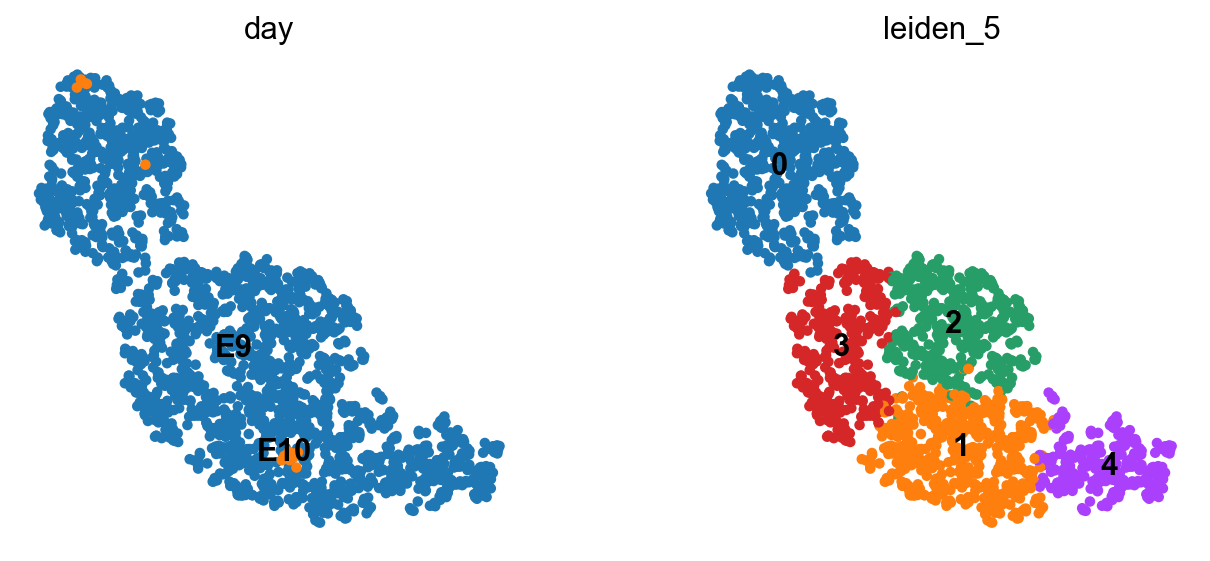

In [15]:
sc.tl.leiden(adata_genes, resolution=0.5, key_added="leiden_5")
sc.pl.umap(adata_genes, color=["day",  'leiden_5'], frameon=False, legend_loc="on data", size=90)

In [17]:
adata_genes.write_h5ad('e_9_10_11_umap__leiden_5.h5ad')

In [18]:
adata_genes

AnnData object with n_obs × n_vars = 2304 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub', 'leiden_sub4', 'leiden_sub2_1', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub7', 'leiden_5'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub2_1', 'leiden_sub2_1_colors', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub3_1_colors', 'leiden_sub3_colors', 'leiden_sub4', 'leiden_sub4_colors', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap', 'leiden_5_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'


In [19]:
auc_mtx

,Ahdc1(+),Alx4(+),Ar(+),Arid3a(+),Arid5a(+),Arid5b(+),Arnt2(+),Ascl2(+),Atf1(+),Atf2(+),...,Zfp932(+),Zfp94(+),Zfp955a(+),Zfp961(+),Zfp990(+),Zfp992(+),Zfx(+),Zgpat(+),Zkscan2(+),Zkscan7(+)
AAACCCACACCCTAGG-1-adata1,0.027354,0.076385,0.000000,0.046213,0.040892,0.054148,0.081157,0.0,0.000000,0.112963,...,0.000000,0.000000,0.008877,0.0,0.0000,0.0,0.054211,0.0,0.000000,0.003548
AAACCCAGTAAGGCTG-1-adata1,0.024465,0.070720,0.000000,0.001604,0.004750,0.059439,0.070739,0.0,0.008536,0.080574,...,0.002097,0.000000,0.000000,0.0,0.0000,0.0,0.070886,0.0,0.000000,0.014053
AAACGAACAGTCGAGA-1-adata1,0.038205,0.274119,0.026771,0.015854,0.029189,0.054664,0.099882,0.0,0.000000,0.088115,...,0.000000,0.089736,0.000000,0.0,0.0000,0.0,0.051931,0.0,0.000000,0.054157
AAACGCTAGCAGCAGT-1-adata1,0.029396,0.026907,0.000671,0.022268,0.052664,0.065337,0.077972,0.0,0.000000,0.103687,...,0.000000,0.000000,0.000000,0.0,0.0000,0.0,0.063456,0.0,0.000000,0.000000
AAAGGATTCTGAATCG-1-adata1,0.023452,0.133386,0.001136,0.032619,0.000000,0.044829,0.073702,0.0,0.000000,0.060151,...,0.000000,0.000000,0.000113,0.0,0.0000,0.0,0.051569,0.0,0.000000,0.005238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CTGGTCTCACCGTACG-1-adata7,0.082178,0.049035,0.000000,0.077374,0.046400,0.080897,0.103304,0.0,0.000000,0.100841,...,0.029835,0.000000,0.019612,0.0,0.0000,0.0,0.065738,0.0,0.000000,0.023938
AATAGAGCACAGTGTT-1-adata8,0.032645,0.080811,0.008829,0.029193,0.034559,0.053767,0.082862,0.0,0.000000,0.075218,...,0.048851,0.000000,0.019308,0.0,0.0000,0.0,0.065517,0.0,0.000000,0.001155
AGTAGCTGTGCAATGG-1-adata8,0.069351,0.197823,0.000000,0.030979,0.000000,0.060793,0.079547,0.0,0.068016,0.081885,...,0.085407,0.072594,0.028546,0.0,0.0000,0.0,0.056132,0.0,0.000000,0.039033
CAACCTCAGATGGGCT-1-adata8,0.039837,0.175872,0.000000,0.120709,0.000000,0.061823,0.047431,0.0,0.000000,0.072714,...,0.027261,0.086121,0.006072,0.0,0.1353,0.0,0.062043,0.0,0.110781,0.000000


In [20]:
adata_genes.obs.index = auc_mtx.index

In [21]:
adata=sc.AnnData(auc_mtx,
           obs=adata_genes.obs,uns=adata_genes.uns,obsm=adata_genes.obsm)

/tmp/ipykernel_4015617/4019417087.py:1: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata=sc.AnnData(auc_mtx,


In [22]:
adata

AnnData object with n_obs × n_vars = 2304 × 420
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub', 'leiden_sub4', 'leiden_sub2_1', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub7', 'leiden_5'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub2_1', 'leiden_sub2_1_colors', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub3_1_colors', 'leiden_sub3_colors', 'leiden_sub4', 'leiden_sub4_colors', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap', 'leiden_5_colors'
    obsm: 'X_pca', 'X_umap'

In [23]:
adata.write_h5ad('e_9_10_11_umap_reg.h5ad')

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scanpy as sc
import numpy as np

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages

# ============================================================
# 1. PAGE SETTINGS — A4 PORTRAIT
# ============================================================

PAGE_W_MM = 210
PAGE_H_MM = 297

PDF_PATH = "E9_10_11_Trigem_regulons_TFs_A4_FINAL.pdf"

# ============================================================
# 2. LAYOUT SETTINGS — ADJUST HERE
# ============================================================

# 6 columns × 6 rows = 36 UMAPs per page
NCOLS = 6
N_BLOCKS = 3
NROWS = N_BLOCKS * 2

# 18 regulon–gene pairs per page
REGS_PER_PAGE = NCOLS * N_BLOCKS

# Page margins (mm)
LEFT_MM = 9
RIGHT_MM = 9
TOP_MM = 26
BOTTOM_MM = 23

# Horizontal spacing (mm)
COL_GAP_MM = 3

# Vertical spacing (mm)
PAIR_GAP_MM = 10
BLOCK_GAP_MM = 13

# Page title
PAGE_TITLE = "Trigem development — Regulons and TFs"
PAGE_TITLE_SIZE = 11

# UMAP titles
PANEL_TITLE_SIZE = 8
TITLE_PAD = 7

# UMAP points
POINT_SIZE = 30

# Remove incomplete final page
REMOVE_INCOMPLETE_LAST_PAGE = True

# Show a preview of the first page in Jupyter
SHOW_PREVIEW = False

# ============================================================
# 3. FONT / PDF SETTINGS
# ============================================================

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": PANEL_TITLE_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 300,
})

# ============================================================
# 4. COLORMAPS
# ============================================================

regulon_cmap = LinearSegmentedColormap.from_list(
    "regulon",
    ["lightgrey", "green"]
)

gene_cmap = LinearSegmentedColormap.from_list(
    "gene",
    ["lightgrey", "red"]
)

# ============================================================
# 5. SELECT REGULONS
# ============================================================

# Find regulons with corresponding gene expression
regulons_all = [
    r for r in adata.var_names
    if r.replace("(+)", "") in adata_genes.var_names
]

print(f"Original regulons: {len(regulons_all)}")

if REMOVE_INCOMPLETE_LAST_PAGE:

    # Number of complete pages
    N_PAGES = len(regulons_all) // REGS_PER_PAGE

    # Retain only complete pages
    regulons = regulons_all[:N_PAGES * REGS_PER_PAGE]

    removed = regulons_all[len(regulons):]

    print(f"Excluded regulons: {len(removed)}")

    if removed:
        print("Excluded:", removed)

else:
    regulons = regulons_all.copy()

    N_PAGES = int(
        np.ceil(len(regulons) / REGS_PER_PAGE)
    )

print(f"Regulons to plot: {len(regulons)}")
print(f"Pairs per page: {REGS_PER_PAGE}")
print(f"Total PDF pages: {N_PAGES}")

# ============================================================
# 6. CALCULATE PANEL DIMENSIONS
# ============================================================

PANEL_W_MM = (
    PAGE_W_MM
    - LEFT_MM
    - RIGHT_MM
    - (NCOLS - 1) * COL_GAP_MM
) / NCOLS

PANEL_H_MM = (
    PAGE_H_MM
    - TOP_MM
    - BOTTOM_MM
    - N_BLOCKS * PAIR_GAP_MM
    - (N_BLOCKS - 1) * BLOCK_GAP_MM
) / NROWS

# ============================================================
# 7. FUNCTION — PANEL POSITION
# ============================================================

def add_panel(fig, col, block, is_gene=False):

    # Horizontal position
    x_mm = (
        LEFT_MM
        + col * (PANEL_W_MM + COL_GAP_MM)
    )

    # Vertical position
    y_top_mm = (
        TOP_MM
        + block * (
            2 * PANEL_H_MM
            + PAIR_GAP_MM
            + BLOCK_GAP_MM
        )
        + (
            PANEL_H_MM + PAIR_GAP_MM
            if is_gene else 0
        )
    )

    # Convert top coordinate to bottom coordinate
    y_bottom_mm = (
        PAGE_H_MM
        - y_top_mm
        - PANEL_H_MM
    )

    ax = fig.add_axes([
        x_mm / PAGE_W_MM,
        y_bottom_mm / PAGE_H_MM,
        PANEL_W_MM / PAGE_W_MM,
        PANEL_H_MM / PAGE_H_MM
    ])

    return ax

# ============================================================
# 8. GENERATE MULTIPAGE A4 PDF
# ============================================================

with PdfPages(PDF_PATH) as pdf:

    for page in range(N_PAGES):

        start = page * REGS_PER_PAGE

        end = min(
            start + REGS_PER_PAGE,
            len(regulons)
        )

        regs_page = regulons[start:end]

        # ----------------------------------------------------
        # CREATE A4 FIGURE
        # ----------------------------------------------------

        fig = plt.figure(
            figsize=(
                PAGE_W_MM / 25.4,
                PAGE_H_MM / 25.4
            ),
            facecolor="white"
        )

        # ----------------------------------------------------
        # PAGE TITLE
        # ----------------------------------------------------

        fig.text(
            0.5,
            1 - 10 / PAGE_H_MM,
            PAGE_TITLE,
            ha="center",
            va="center",
            fontsize=PAGE_TITLE_SIZE,
            fontweight="bold"
        )

        # ----------------------------------------------------
        # REGULON AND GENE UMAPs
        # ----------------------------------------------------

        for i, reg in enumerate(regs_page):

            gene = reg.replace("(+)", "")

            block = i // NCOLS
            col = i % NCOLS

            # Create axes
            ax_reg = add_panel(
                fig,
                col,
                block,
                is_gene=False
            )

            ax_gene = add_panel(
                fig,
                col,
                block,
                is_gene=True
            )

            # -----------------------------------------------
            # REGULON — GREEN
            # -----------------------------------------------

            sc.pl.umap(
                adata,
                color=reg,
                ax=ax_reg,
                show=False,
                title=f"{reg} regulon",
                cmap=regulon_cmap,
                size=POINT_SIZE,
                frameon=False,
                colorbar_loc=None
            )

            # -----------------------------------------------
            # GENE / TF — RED
            # -----------------------------------------------

            sc.pl.umap(
                adata_genes,
                color=gene,
                ax=ax_gene,
                show=False,
                title=f"{gene} gene",
                cmap=gene_cmap,
                size=POINT_SIZE,
                frameon=False,
                colorbar_loc=None
            )

            # -----------------------------------------------
            # CLEAN AXES
            # -----------------------------------------------

            for ax in (ax_reg, ax_gene):

                ax.set_xlabel("")
                ax.set_ylabel("")

                ax.set_xticks([])
                ax.set_yticks([])

                ax.set_title(
                    ax.get_title(),
                    fontsize=PANEL_TITLE_SIZE,
                    pad=TITLE_PAD
                )

                ax.margins(0.02)

        # ----------------------------------------------------
        # SAVE EXACT A4 PAGE
        # ----------------------------------------------------

        # Do not use bbox_inches="tight"!
        # This preserves the exact 210 × 297 mm page size.

        pdf.savefig(
            fig,
            facecolor="white"
        )

        if SHOW_PREVIEW and page == 0:
            plt.show()

        plt.close(fig)

        print(
            f"Saved page {page + 1}/{N_PAGES}"
        )

# ============================================================
# 9. FINISHED
# ============================================================

print("\n==========================================")
print("PDF successfully generated")
print(f"File: {PDF_PATH}")
print(f"Pages: {N_PAGES}")
print(f"Page size: A4 Portrait (210 × 297 mm)")
print(f"Regulon–gene pairs: {len(regulons)}")
print("==========================================")


Original regulons: 420
Excluded regulons: 6
Excluded: ['Zfp990(+)', 'Zfp992(+)', 'Zfx(+)', 'Zgpat(+)', 'Zkscan2(+)', 'Zkscan7(+)']
Regulons to plot: 414
Pairs per page: 18
Total PDF pages: 23
Saved page 1/23
Saved page 2/23
Saved page 3/23
Saved page 4/23
Saved page 5/23
Saved page 6/23
Saved page 7/23
Saved page 8/23
Saved page 9/23
Saved page 10/23
Saved page 11/23
Saved page 12/23
Saved page 13/23
Saved page 14/23
Saved page 15/23
Saved page 16/23
Saved page 17/23
Saved page 18/23
Saved page 19/23
Saved page 20/23
Saved page 21/23
Saved page 22/23
Saved page 23/23


In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

grey_green = LinearSegmentedColormap.from_list(
    "grey_green", ["#e0e0e0", "#a1d99b", "#31a354", "#00441b"]
)

fig = sc.pl.umap(
    adata,
    color=["Bhlhe23(+)", "Creb5(+)", "E2f2(+)", "E2f7(+)", "E2f8(+)", "Elf4(+)", "Etv5(+)", "Gli3(+)", "Hmga2(+)",
           "Ikzf2(+)", "Irf6(+)","Irx4(+)", "Isl1(+)", "Klf6(+)", "Klf7(+)", "Lef1(+)", "Lhx2(+)", "Maf(+)", "Msx2(+)",
           "Nfat5(+)", "Nfib(+)", "Nfic(+)", "Nhlh1(+)", "Onecut2(+)","Pou3f1(+)", "Pou4f1(+)", 'Zfp91(+)',
           #"Prrx1(+)",
           "Rarg(+)", "Rest(+)", "Shox2(+)", "Six1(+)", "Smad3(+)",
           'Shox2(+)', 'Nhlh1(+)', 'Onecut2(+)', 'Pou4f1(+)',
          ],
    ncols=6,
    cmap=grey_green,
   # vmax="p99",
    size=150,
    frameon=False,
    return_fig=True,
    show=False,
)

for ax in fig.axes:                      # rasterize dots for Illustrator
    for coll in ax.collections:
        coll.set_rasterized(True)

#fig.savefig("umap_regulons_green.svg", dpi=300, bbox_inches="tight")
plt.show()